In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import sys
import astropy as ast
from astropy.io import ascii
import matplotlib.pyplot as plt
import pandas as pd
import glob
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm, Normalize
from metrics import fit_plotter_flux, fit_plotter_flux_v2, mean_med_flux, mean_med_flux_v2, offset_warning, offset_warning_v2,compute_lomb_scargle, plot_periodogram,plot_phase_fold
from view_and_clean import individual_plotter, df_extract, individual_plotter_v2, df_extract_v2, offset_corrector


In [2]:
# stats_2022 = pd.read_csv('summary_results07.csv')
stats_2025 = pd.read_csv('summary_results09.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'summary_results09.csv'

In [ ]:
skypatrolV2 = pd.read_csv('sub2025_V2/index.csv')

def filematcher(ra, dec):
    # Match by RA and Dec
    match = skypatrolV2[(np.isclose(skypatrolV2['ra_deg'], ra, atol=1e-5)) & (np.isclose(skypatrolV2['dec_deg'], dec, atol=1e-5))]
    if not match.empty:
        return match.iloc[0]['asas_sn_id']
    else:
        return None

In [ ]:
coords = pd.read_csv('merged_smc_lmc_coords.csv', comment='#', sep="\\s+", names=['RA', 'DEC'])

In [ ]:
def compare_plots(target):
    RA = coords['RA'].iloc[target]
    dec = coords['DEC'].iloc[target]
    asas_id = int(filematcher(RA, dec))
    print(f'ASAS-SN ID: {int(asas_id)}')
    print(offset_warning(target, g=True, newfiles=True))
    individual_plotter(target, report=True)
    fit_plotter_flux(target, newfiles=True)
    print(offset_warning_v2(target, filematcher_result=asas_id, g=True, newfiles=True))
    individual_plotter_v2(target, filematcher_result=asas_id, report=True)
    fit_plotter_flux_v2(target, filematcher_result=asas_id, newfiles=True)

# compare_plots(200)
# compare_plots(202)
# compare_plots(8)
# compare_plots(294)
# fit_plotter_flux(294, newfiles=False)
# compare_plots(16)
# compare_plots(299)
# compare_plots(172)
# fit_plotter_flux(172, newfiles=True)
# fit_plotter_flux(172, g=False, newfiles=False)
# compare_plots(78)

In [2]:
offsets_df = pd.read_csv('offsets.csv')
# stats_2025 = pd.read_csv('summary_results12.csv')

## Correcting offsets in flux space:

In [7]:
# # print('8 = discarding telescopes only')
# target=110
# print(mean_med_flux(target, g=True, correct_offsets=False))
# lombs1 = compute_lomb_scargle(target, auto=False, median=False, subtract_median=False, samples_per_peak=10, report=False, correct_offsets=False)
# best_period = lombs1['best_period']
# print(best_period)
# plot_periodogram(target, lombs1['frequency'], lombs1['power'], lombs1['best_frequency'], lombs1['false_alarm_level'], lombs1['peaks'], lombs1['observation_period'], show_best=True)
# plot_phase_fold(target, lombs1['best_period'], phase_bins=2)

# offset_corrector(target,additive=False, show=True)
# print(mean_med_flux(target, g=True, correct_offsets=True))
# lombs2 = compute_lomb_scargle(target, auto=False, median=False, subtract_median=False, samples_per_peak=10, report=False, correct_offsets=True)
# best_period = lombs2['best_period']
# print(best_period)
# plot_periodogram(target, lombs2['frequency'], lombs2['power'], lombs2['best_frequency'], lombs2['false_alarm_level'], lombs2['peaks'], lombs2['observation_period'], show_best=True)
# plot_phase_fold(target, lombs2['best_period'], phase_bins=2, correct_offsets=True)
# plot_phase_fold(target, lombs1['best_period'], phase_bins=2, correct_offsets=True)



## Correcting offsets in magnitude space

In [8]:
# print('8 = discarding telescopes only')
# target=110
# offset_corrector(target,additive=False, mag_space=True, show=True)
# offset_corrector(target,additive=True, mag_space=True, show=True)

discarding telescopes and correcting offsets


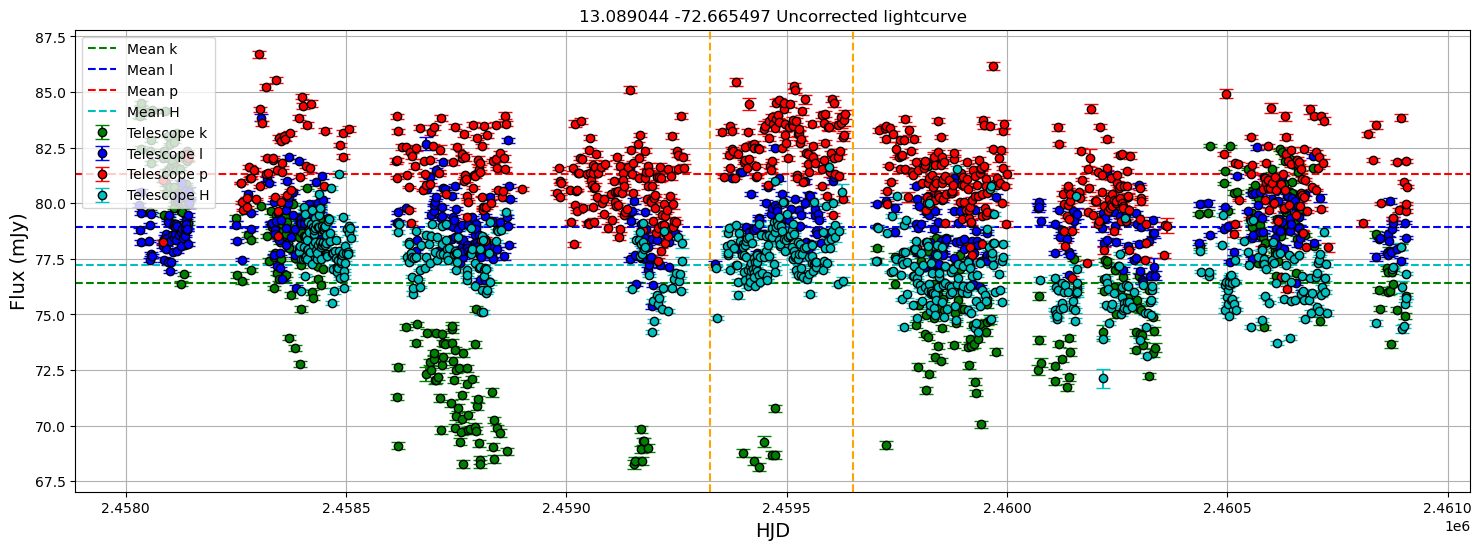

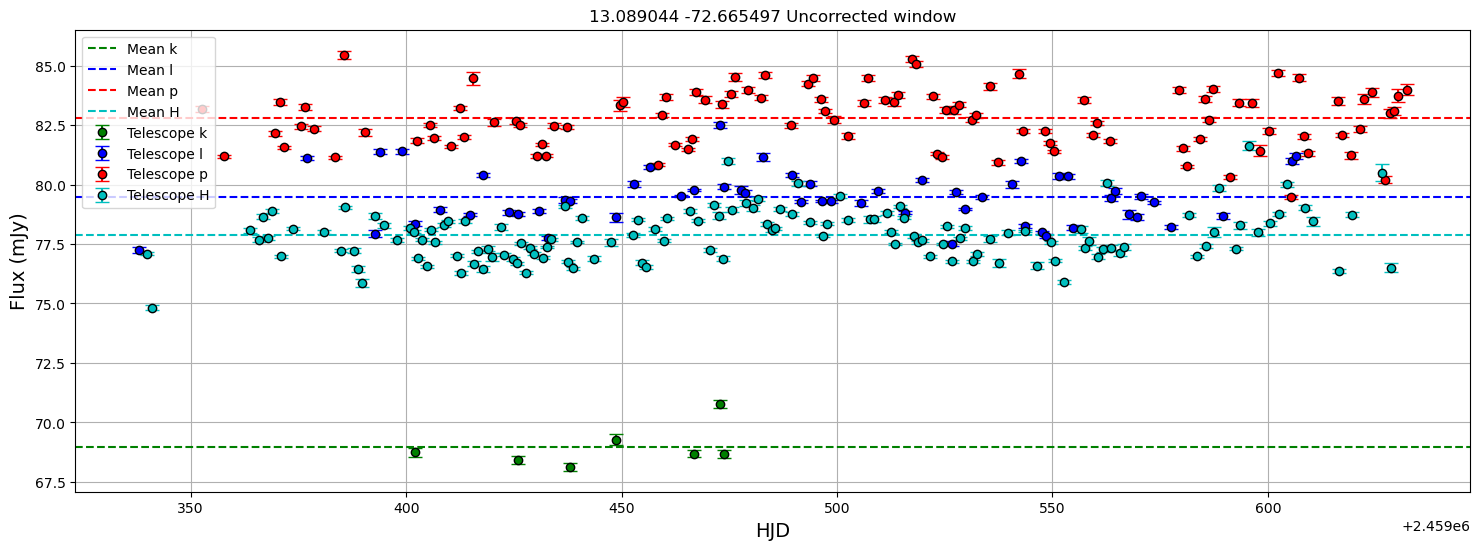

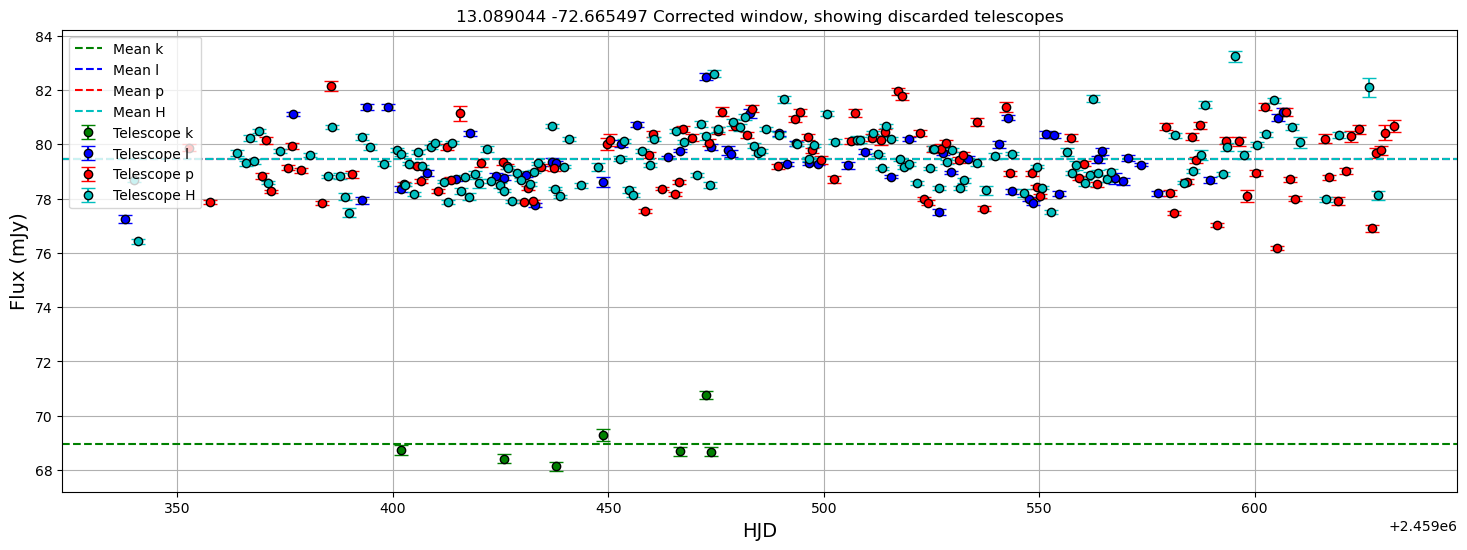

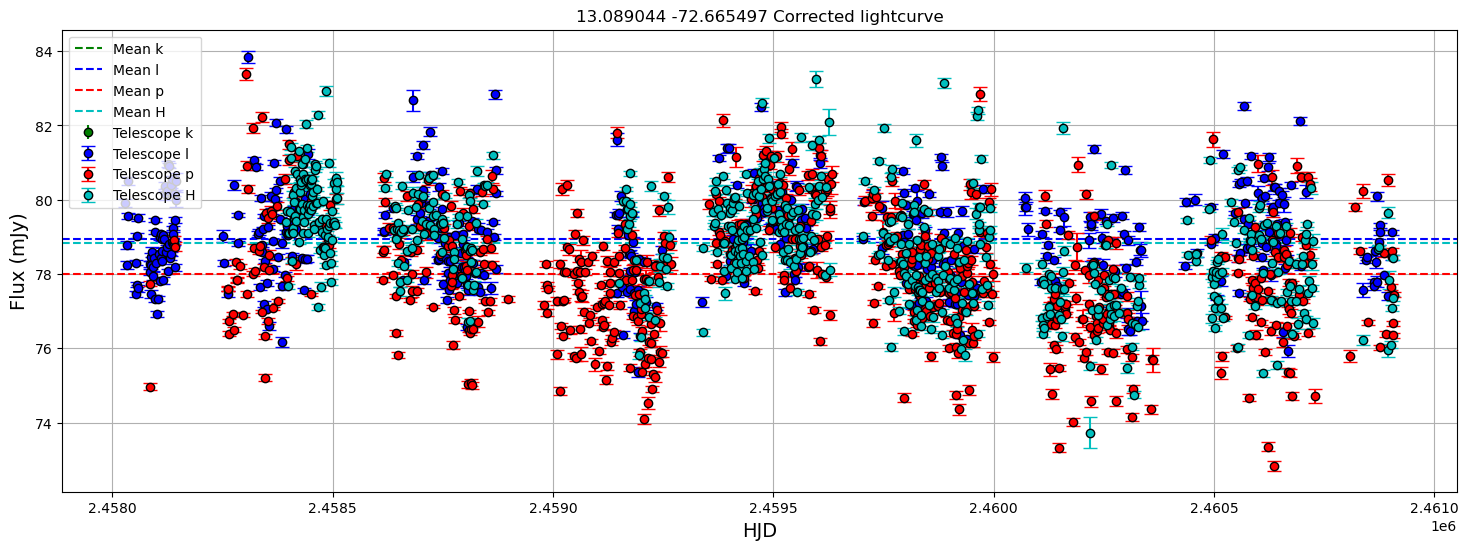

(                JD           HJD             UT_date           IMAGE  FWHM  \
 1     2.458030e+06  2.458030e+06  2017-10-03.0646519  coadd_bl007387  1.64   
 2     2.458033e+06  2.458033e+06  2017-10-06.1344646  coadd_bl008628  1.61   
 5     2.458034e+06  2.458034e+06  2017-10-07.2812664  coadd_bl009132  1.48   
 6     2.458035e+06  2.458035e+06  2017-10-08.2521016  coadd_bl009516  1.56   
 8     2.458036e+06  2.458036e+06  2017-10-09.2146868  coadd_bl009879  1.62   
 ...            ...           ...                 ...             ...   ...   
 2107  2.460905e+06  2.460905e+06  2025-08-17.3587939  coadd_bH700539  1.44   
 2108  2.460905e+06  2.460905e+06  2025-08-17.9407767  coadd_bp619265  1.62   
 2109  2.460906e+06  2.460906e+06  2025-08-18.1394135  coadd_bH700778  1.45   
 2110  2.460907e+06  2.460907e+06  2025-08-19.0089798  coadd_bp619710  1.50   
 2111  2.460907e+06  2.460907e+06  2025-08-19.8806285  coadd_bp619978  1.99   
 
       Diff   Limit     mag  mag_err  counts  coun

In [9]:
print('discarding telescopes and correcting offsets')
offset_corrector(110, additive=True, show=True, show_window=True)

In [ ]:
offset_corrector(156,additive=False, show=True, show_window=True)
offset_corrector(403, additive=False, show=True, show_window=True)
# 426

# Visual check lightcurves:

In [ ]:
counter = 0
for index, row in offsets_df.iterrows():
    if row['visual_check'] == 1:
        ra = row['ra']
        dec = row['dec']
        target = int(row['target'])
        print(f"\nTarget {target} at RA: {ra}, Dec: {dec}")
        offset_corrector(target, additive=False, show=True)
        counter += 1
print(f"\nTotal targets with visual_check == 1: {counter}")

In [ ]:
counter = 0
for index, row in offsets_df.iterrows():
    if row['discard_lc'] == 1:
        ra = row['ra']
        dec = row['dec']
        target = int(row['target'])
        print(f"\nTarget {target} at RA: {ra}, Dec: {dec}")
        offset_corrector(target, additive=False, show=True)
        counter += 1
print(f"\nTotal targets with discard_lc == 1: {counter}")

Best frequency: 0.459059 1/day, Best period: 2.18 days, Max power: 0.902, False alarm probability: 0.000e+00
False alarm level for 1.0%: 8.578e-03


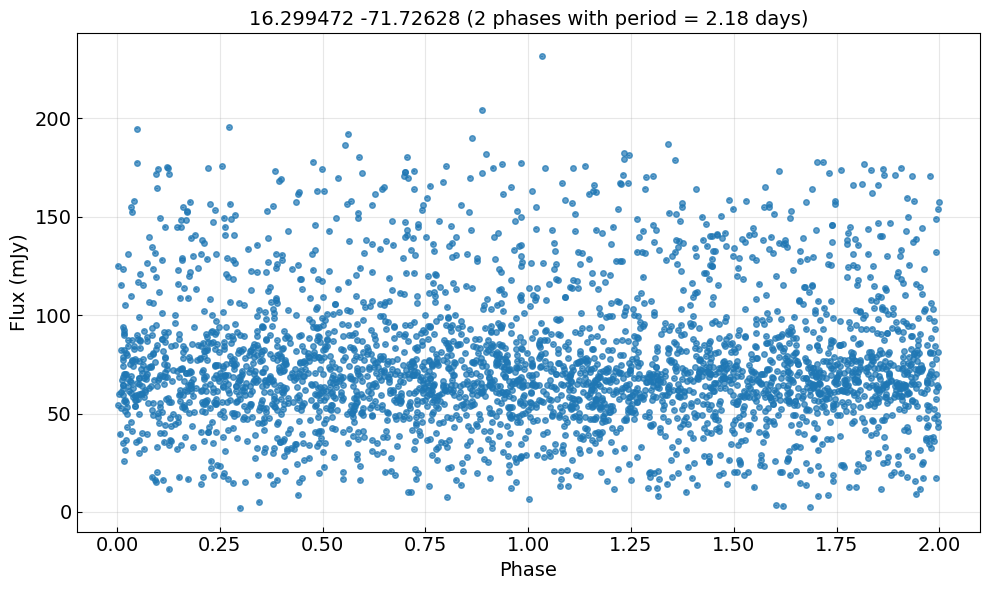

Average scatter (amplitude) per 10 point phase bin: 102.141 mJy


np.float64(102.14142848806469)

In [15]:
lombs1 = compute_lomb_scargle(320, auto=False, median=False, subtract_median=False, samples_per_peak=10)
plot_phase_fold(320, lombs1['best_period'], phase_bins=2)

# Looking at lightcurves of all offset telescopes:

In [ ]:
for row in stats_2025.index:
    if stats_2025['offset_flag'].iloc[row] == 1:
        print(row)
        
        # # Get coordinates for this target
        # RA = coords['RA'].iloc[row]
        # dec = coords['DEC'].iloc[row]
        
        # # Check if this target is already in the CSV
        # existing_entry = offsets_df[offsets_df['target'] == row]
        
        # if existing_entry.empty:
        #     # Add new row with coordinates and target info, leave other columns blank
        #     new_row = {
        #         'ra': RA,
        #         'dec': dec, 
        #         'target': row,
        #         'offset_number': '',
        #         'offset_telescopes': '',
        #         'discard_telescopes': '',
        #         'time_start': '',
        #         'time_end': '',
        #         'visual_check': '',
        #         'discard_lc': ''
        #     }
        #     offsets_df = pd.concat([offsets_df, pd.DataFrame([new_row])], ignore_index=True)
        #     print(f"Added target {row} (RA: {RA}, Dec: {dec}) to offsets.csv")
        # else:
        #     print(f"Target {row} already exists in offsets.csv")
        # offset_warning(row, newfiles=True) 
        # fit_plotter_flux(row, newfiles=True)
        offset_corrector(row,additive=False, show=True)

# Save the updated CSV
# offsets_df.to_csv('offsets.csv', index=False)
# print(f"\nUpdated offsets.csv with {len(offsets_df)} entries")

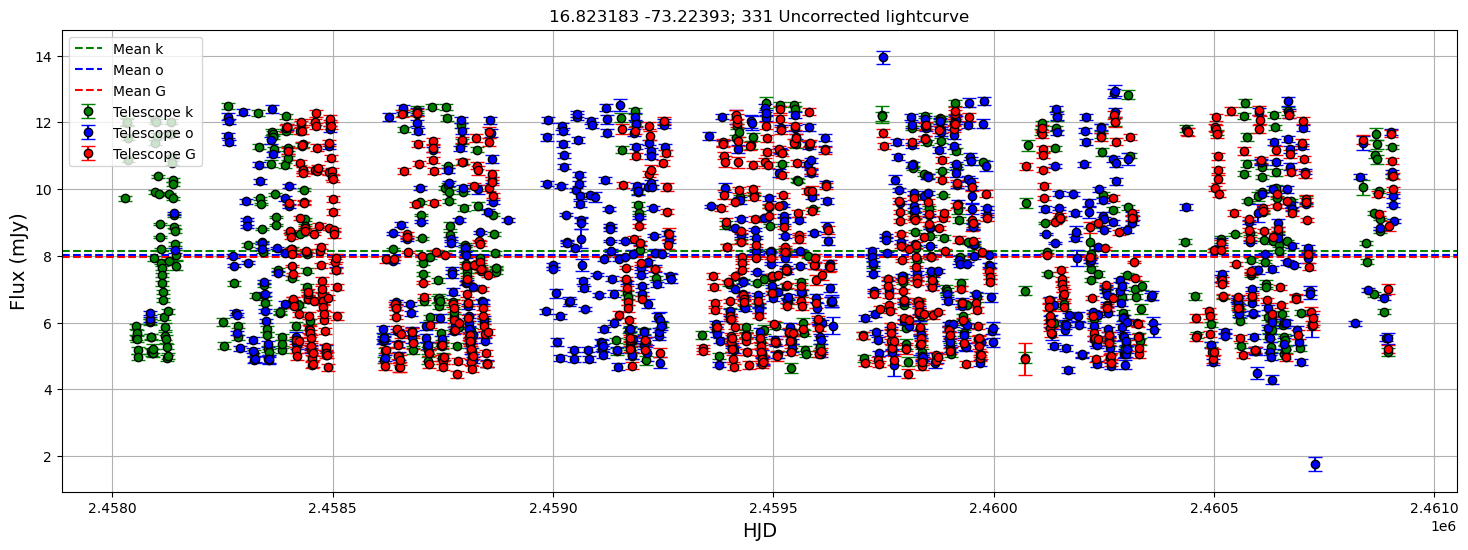

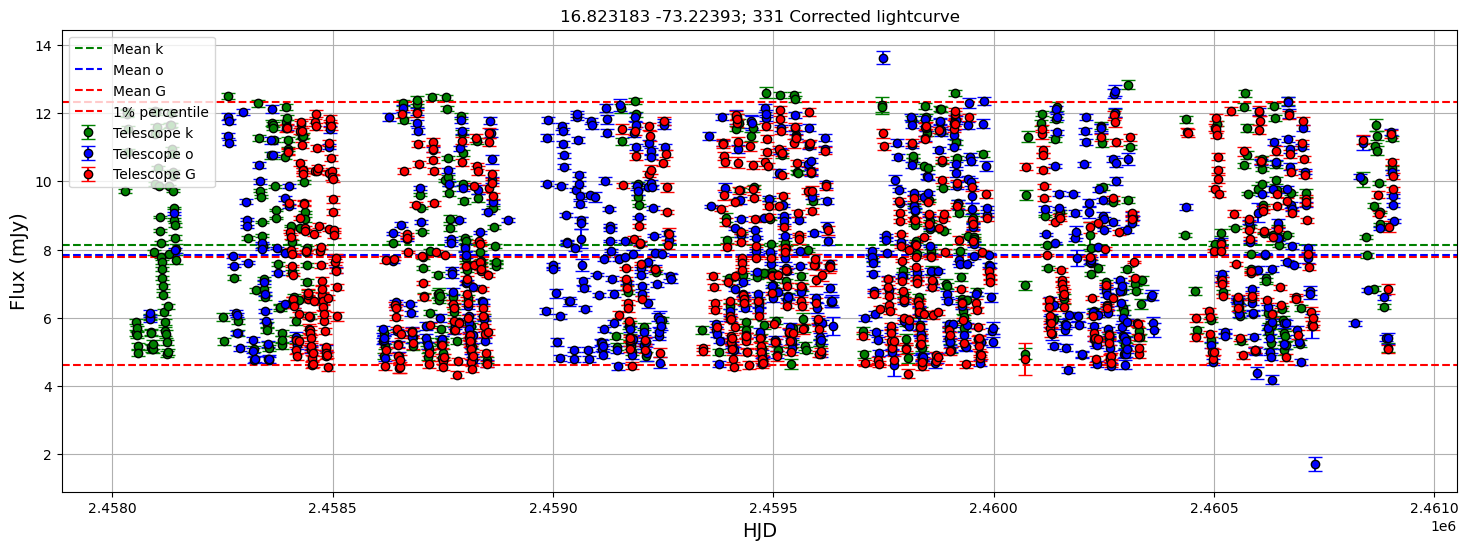

(                JD           HJD             UT_date           IMAGE  FWHM  \
 0     2.458030e+06  2.458030e+06  2017-10-03.0646511  coadd_bk007392  2.22   
 1     2.458033e+06  2.458033e+06  2017-10-06.1344645  coadd_bk008633  2.00   
 2     2.458034e+06  2.458034e+06  2017-10-07.2812663  coadd_bk009137  1.52   
 3     2.458035e+06  2.458035e+06  2017-10-08.2521018  coadd_bk009521  2.00   
 4     2.458036e+06  2.458036e+06  2017-10-09.2146870  coadd_bk009884  2.26   
 ...            ...           ...                 ...             ...   ...   
 1730  2.460905e+06  2.460905e+06  2025-08-17.3587945  coadd_bG697367  1.47   
 1731  2.460905e+06  2.460905e+06  2025-08-17.9407763  coadd_bo627959  1.44   
 1732  2.460906e+06  2.460906e+06  2025-08-18.1394141  coadd_bG697606  1.53   
 1733  2.460907e+06  2.460907e+06  2025-08-19.0089792  coadd_bo628404  1.53   
 1734  2.460907e+06  2.460907e+06  2025-08-19.8806283  coadd_bo628672  1.45   
 
       Diff   Limit        mag  mag_err   counts  

In [4]:
offset_corrector(331)

In [ ]:
offset_corrector(331)

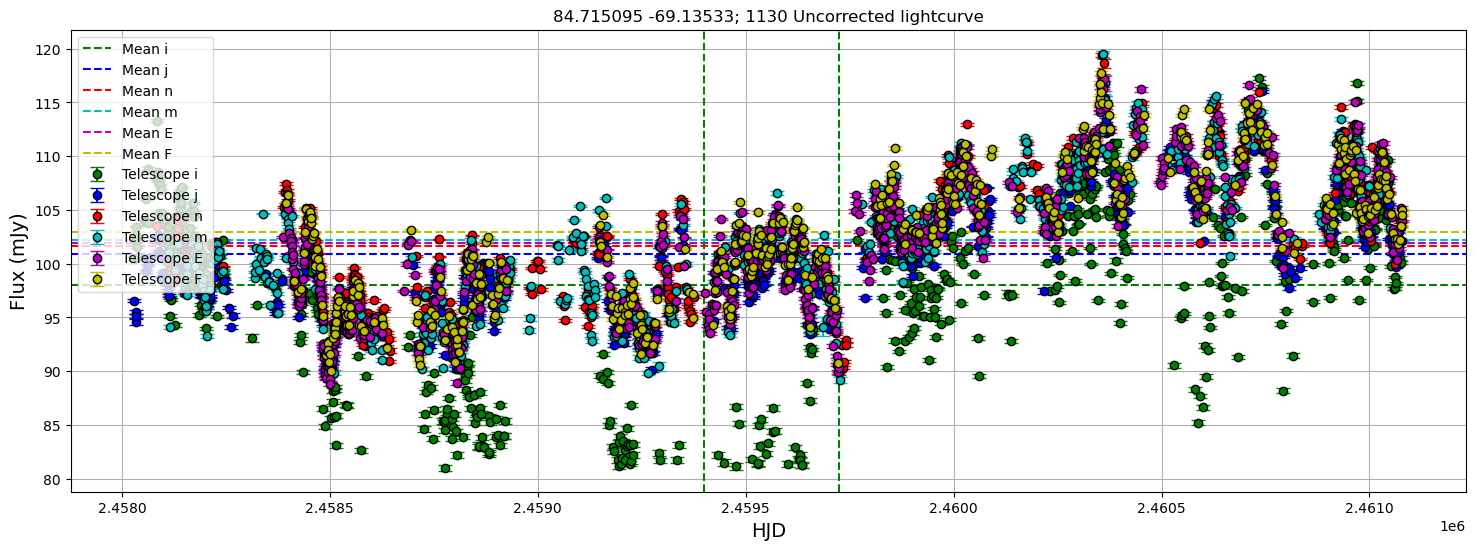

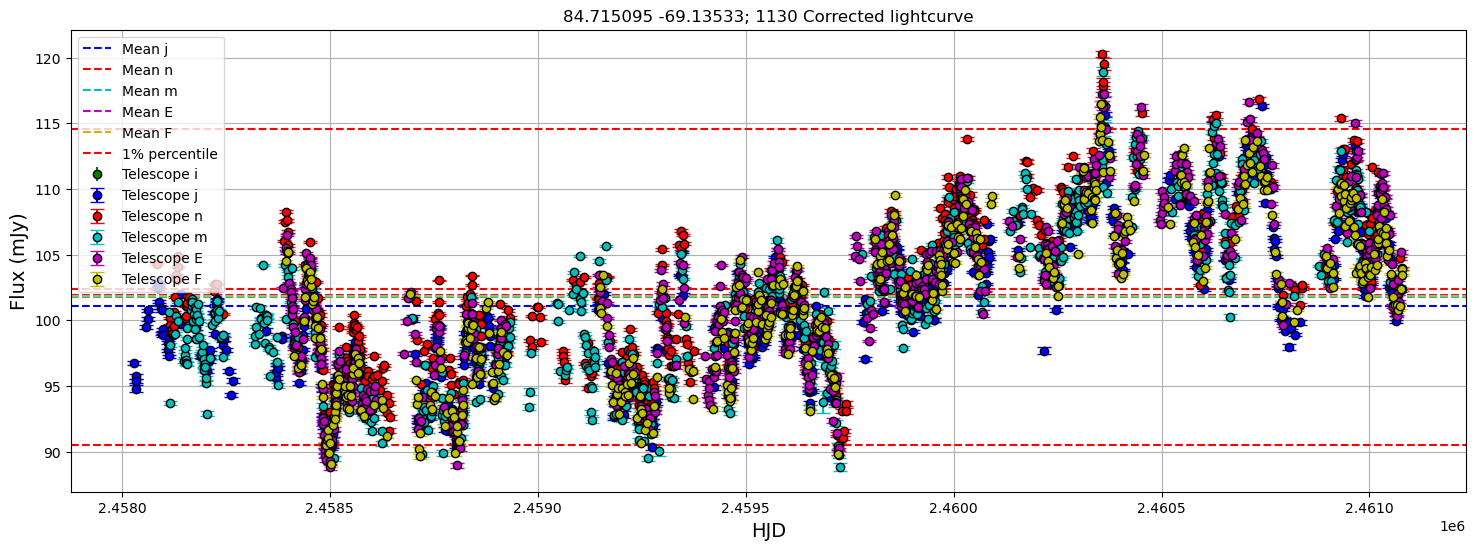

(                JD           HJD             UT_date           IMAGE  FWHM  \
 0     2.458030e+06  2.458030e+06  2017-10-03.2897829  coadd_bj007581  2.22   
 1     2.458033e+06  2.458033e+06  2017-10-06.2870759  coadd_bj008763  2.01   
 2     2.458034e+06  2.458034e+06  2017-10-07.3700870  coadd_bj009214  1.98   
 3     2.458035e+06  2.458035e+06  2017-10-08.3669386  coadd_bj009606  2.20   
 4     2.458059e+06  2.458059e+06  2017-11-01.2584975  coadd_bj017630  2.17   
 ...            ...           ...                 ...             ...   ...   
 3207  2.461077e+06  2.461077e+06  2026-02-05.2002113  coadd_bF762507  2.22   
 3208  2.461078e+06  2.461078e+06  2026-02-06.0768660  coadd_bj946354  1.68   
 3209  2.461078e+06  2.461078e+06  2026-02-06.1467004  coadd_bE767770  1.53   
 3210  2.461079e+06  2.461079e+06  2026-02-07.1488603  coadd_bF763365  2.37   
 3211  2.461080e+06  2.461080e+06  2026-02-08.0260709  coadd_bF763694  2.18   
 
       Diff   Limit        mag  mag_err   counts  

In [5]:
offset_corrector(1130)